# 2.1.- Regresión Lineal OLS

La **regresión lineal** es un modelo estadístico utilizado para estudiar la relación entre una variable independiente $x$ y una variable dependiente $y$.

La ecuación de una recta es:

$$\large \hat{y} = \beta_1 x + \beta_0$$

donde:

* $\beta_1$ = pendiente (indica cuánto cambia $y$ cuando $x$ aumenta en una unidad).
* $\beta_0$ = intercepto (indica el valor de $y$ cuando $x=0$).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## Datos de ejemplo: [Anscombe's quartet](https://es.wikipedia.org/wiki/Cuarteto_de_Anscombe)

Para ilustrae La Regresión LinealS)**, usaremos un conjunto de datos clásico: el **Cuarteto de Anscombe**.  

Este dataset muestra cómo **diferentes distribuciones de datos pueden tener las mismas estadísticas descriptivas (media, varianza, correlación, regresión lineal)**, pero comportarse de forma muy distinta al graficarlos.

Trabajaremos con el primer grupo de datos $(x, y)$.

In [ ]:
# Cargar dataset de Anscombe quintet
url = 'https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/Anscombe_quintet_data.csv'
df = pd.read_csv(url).sort_values(by='x1235', ascending=True)

# Definimos las variables de interés
df["x"] = df["x1235"]
df["y"] = df["y1"]

df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,4.26
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,5.68
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,7.24
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,4.82
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,6.95


## Visualización de los datos

Antes de ajustar el modelo de regresión, es fundamental **explorar gráficamente los datos**.  

Usaremos un gráfico de dispersión (*scatter plot*) con [Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html):

* Eje $x$: variable independiente.
* Eje $y$: variable dependiente.
* Cada punto $(x_i, y_i)$ representa una observación del ataset.


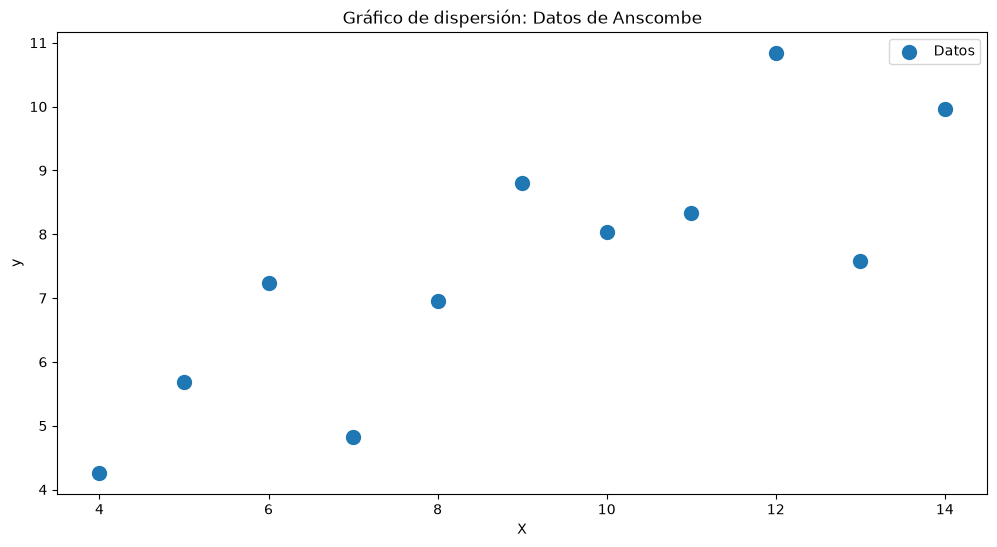

In [ ]:
fig = plt.figure(figsize=(12, 6))
plt.scatter(df["x"], df["y"], s=100, label="Datos")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Gráfico de dispersión: Datos de Anscombe")
plt.legend()
plt.show()

## [Mínimos Cuadrados Ordinarios](https://es.wikipedia.org/wiki/M%C3%ADnimos_cuadrados) (OLS)

El objetivo de OLS es encontrar la recta que mejor ajusta los datos, minimizando la suma de los errores al cuadrado.  

Ecuación de la recta:

$$\large \hat{y} = \beta_1 x + \beta_0$$

Las fórmulas de OLS son:

Para la pendiente $\beta_1$:

$$\large \beta_1 = \frac{ \sum \left( (x_i - \overline{x}) (y_i - \overline{y}) \right) } {\sum  (x_i - \overline{x})^2}$$

Para el intercepto $\beta_0$:

$$\large \beta_0 = \overline{y} - \beta_1 \overline{x}$$

---

Funciones útiles en Python:

* [`np.mean(x)`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html) → calcula la media.
* [`np.sum(x)`](https://numpy.org/doc/stable/reference/generated/numpy.sum.html) → suma todos los elementos.
* `x**2` → eleva al cuadrado cada elemento.

In [ ]:
# Extraer las variables
x = df["x"].values
y = df["y"].values

# Medias
x_mean = np.mean(x)
y_mean = np.mean(y)

# Fórmulas OLS
beta_1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
beta_0 = y_mean - beta_1 * x_mean

print("Pendiente (beta_1):", beta_1)
print("Intercepto (beta_0):", beta_0)

Pendiente (beta_1): 0.5000909090909091
Intercepto (beta_0): 3.0000909090909076


## Interpretación de los coeficientes

Con el cálculo anterior hemos obtenido:

* $\beta_1$ = pendiente → cuánto aumenta (o disminuye) $y$ cuando $x$ crece en una unidad.
* $\beta_0$ = intercepto → valor de $y$ cuando $x = 0$.

## Recta ajustada a los datos

Con los coeficientes $\beta_0$ y $\beta_1$, podemos calcular los valores predichos $\hat{y}$ para cada observación $x_i$:

$$\large \hat{y}_i = \beta_1 x_i + \beta_0$$

Estos valores $\hat{y}$ se añaden a nuestro DataFrame como una nueva columna **`y_pred`**, que representa la recta de regresión ajutada.


In [ ]:
# Calcular valores predichos y guardarlos en el DataFrame
df["y_pred"] = beta_1 * df["x"] + beta_0

df.head()

,x1235,y1,y2,y3,y5,x4,y4,x,y,y_pred
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,4.26,5.000455
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,5.68,5.500545
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,7.24,6.000636
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,4.82,6.500727
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,6.95,7.000818


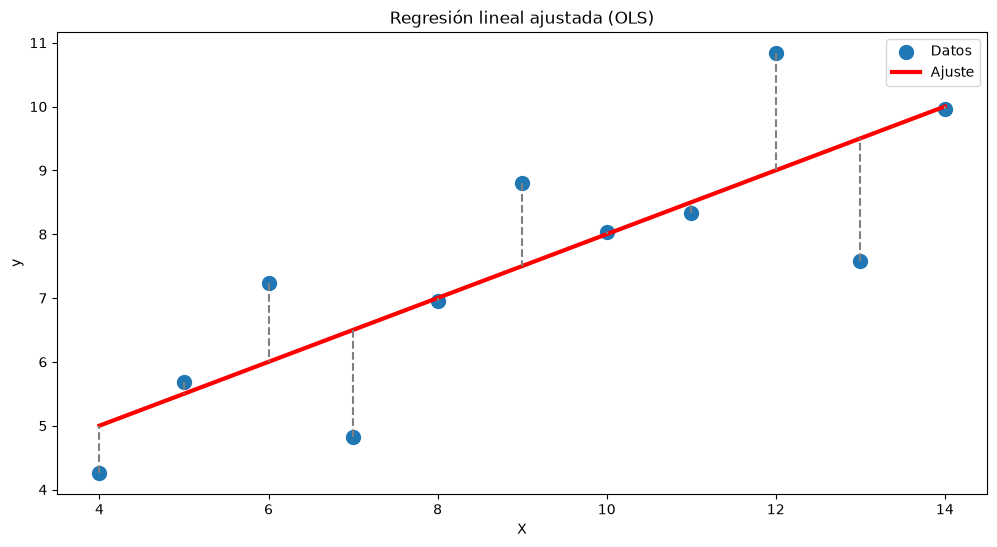

In [ ]:
fig = plt.figure(figsize=(12, 6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Recta ajustada
plt.plot(df["x"], df["y_pred"], color="red", lw=3, label="Ajuste")

# Líneas verticales = residuos (y - y_pred)
for i in range(len(df)):
    plt.plot([df["x"].iloc[i], df["x"].iloc[i]],
             [df["y"].iloc[i], df["y_pred"].iloc[i]],
             color="gray", linestyle="--")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión lineal ajustada (OLS)")
plt.legend()
plt.show()

## Usando álgebra lineal y la [ecuación normal](http://mlwiki.org/index.php/Normal_Equation)

Podemos tratar el problema de la regresión lineal como un [sistema de ecuaciones lineales](https://es.wikipedia.org/wiki/Sistema_de_ecuaciones_lineales):

$$\large X \beta = y $$

donde $\beta$ es el vector de coeficientes.  
Por ejemplo, para la primera observación:

$$\large \beta_1 (x_1)^1 + \beta_0 (x_1)^0 = y_1 $$

---

Esto se puede escribir en forma matricial:

$$ X^T X \beta = X^T y $$

y resolviendo para $\beta$ obtenemos:

$$ \beta = (X^T X)^{-1} X^T y $$

---

Notas útiles:

* $X^T$ es la [traspuesta de una matriz](https://es.wikipedia.org/wiki/Traspuesta) (en Python: `.T`).  
* La inversa de una matriz se calcula con [`numpy.linalg.inv`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.inv.html).  


In [ ]:
# Construcción de la matriz de diseño: [x, 1]
X1 = np.column_stack((np.ones(len(df)), df["x"]))

# Vector de salida
y_vec = df["y"].values

# Aplicamos la ecuación normal
betas = np.linalg.inv(X1.T @ X1) @ X1.T @ y_vec

print("Pendiente (beta_1):", betas[1])
print("Intercepto (beta_0):", betas[0])

Pendiente (beta_1): 0.5000909090909095
Intercepto (beta_0): 3.000090909090903
